Делаем проектирования архитектуры глубокой свёрточной нейронной сети для классификации набора изображений из 9 лабораторной

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
# Функция загрузки изображений
def load_images_from_folder(folder, target_size=(512, 512)):
    images = []
    labels = []
    for label in os.listdir(folder):
        if label in ['cactus', 'fern', 'rose', 'sunflower', 'tulip']:
            label_folder = os.path.join(folder, label)
            if os.path.isdir(label_folder):
                for filename in os.listdir(label_folder):
                    img_path = os.path.join(label_folder, filename)
                    img = cv2.imread(img_path)
                    if img is not None:
                        img_resized = cv2.resize(img, target_size)
                        images.append(img_resized)
                        labels.append(label)
    return images, labels
# Путь к папке с изображениями
folder_path = "..\\static\\csv\\dataset"
images, labels = load_images_from_folder(folder_path)

images = np.array(images)
labels = np.array(labels)
# Разделение данных на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(images, labels, test_size=0.2, random_state=42)

Выполним предобработку изображений

In [ ]:
# Функция предобработки изображений
def preprocess_images(images):
    processed_images = []
    for img in images:
        img_resized = cv2.resize(img, (128, 128))  
        img_gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)  # Преобразование в оттенки серого
        img_eq = cv2.equalizeHist(img_gray)  # Усовершенствование изображения
        processed_images.append(img_eq.reshape(128, 128, 1))  # Добавление новой оси
    return np.array(processed_images)
processed_images = preprocess_images(X_train)

Агментируем данные

In [ ]:
# Функция аугментации данных
def augment_data(images, labels):
    datagen = ImageDataGenerator(
        rotation_range=15,
        width_shift_range=0.2,
        height_shift_range=0.2,
        shear_range=0.2,
        zoom_range=0.2,
        horizontal_flip=True,
        fill_mode='nearest'
    )

    augmented_images = []
    augmented_labels = []

    for label in np.unique(labels):
        label_images = images[labels == label]
        for img in label_images:
            img = img.reshape((1,) + img.shape)
            for _ in range(10):  # Генерация 10 аугментированных изображений
                aug_iter = datagen.flow(img)
                aug_img = next(aug_iter)[0].astype(np.uint8)
                augmented_images.append(aug_img)
                augmented_labels.append(label)

    return np.array(augmented_images), np.array(augmented_labels)
augmented_images, augmented_labels = augment_data(processed_images, y_train)
# Кодировка меток
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(augmented_labels)
# Предобработка тестовых данных
X_test_processed = preprocess_images(X_test)

Создадим модель AlexNet

In [10]:
# Создание модели AlexNet
def create_alexnet(input_shape, num_classes):
    model = models.Sequential()
    model.add(layers.Conv2D(96, kernel_size=(11, 11), strides=(4, 4), activation='relu', input_shape=input_shape))
    model.add(layers.MaxPooling2D(pool_size=(3, 3), strides=(2, 2)))
    model.add(layers.Conv2D(256, kernel_size=(5, 5), padding='same', activation='relu'))
    model.add(layers.MaxPooling2D(pool_size=(3, 3), strides=(2, 2)))
    model.add(layers.Conv2D(384, kernel_size=(3, 3), padding='same', activation='relu'))
    model.add(layers.Conv2D(384, kernel_size=(3, 3), padding='same', activation='relu'))
    model.add(layers.Conv2D(256, kernel_size=(3, 3), padding='same', activation='relu'))
    model.add(layers.MaxPooling2D(pool_size=(3, 3), strides=(2, 2)))
    model.add(layers.Flatten())
    model.add(layers.Dense(4096, activation='relu'))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(4096, activation='relu'))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(num_classes, activation='softmax'))

    return model

In [11]:
input_shape = (128, 128, 1)  # Одноканальное изображение
num_classes = len(np.unique(labels))
model = create_alexnet(input_shape, num_classes)
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

c:\Users\annal\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Обучим модель

In [ ]:
# Обучение модели
history = model.fit(augmented_images, y_train_encoded, epochs=30, batch_size=32, validation_data=(X_test_processed, label_encoder.transform(y_test)))

Epoch 1/30
480/480 ━━━━━━━━━━━━━━━━━━━━ 124s 256ms/step - accuracy: 0.2228 - loss: 5.5490 - val_accuracy: 0.1979 - val_loss: 1.6180
Epoch 2/30
480/480 ━━━━━━━━━━━━━━━━━━━━ 104s 216ms/step - accuracy: 0.2414 - loss: 1.5920 - val_accuracy: 0.2760 - val_loss: 1.5888
Epoch 3/30
480/480 ━━━━━━━━━━━━━━━━━━━━ 124s 258ms/step - accuracy: 0.2563 - loss: 1.5883 - val_accuracy: 0.2578 - val_loss: 1.5707
Epoch 4/30
480/480 ━━━━━━━━━━━━━━━━━━━━ 97s 201ms/step - accuracy: 0.2171 - loss: 1.6248 - val_accuracy: 0.2656 - val_loss: 1.5996
Epoch 5/30
480/480 ━━━━━━━━━━━━━━━━━━━━ 88s 183ms/step - accuracy: 0.2302 - loss: 1.6024 - val_accuracy: 0.3047 - val_loss: 1.5185
Epoch 6/30
480/480 ━━━━━━━━━━━━━━━━━━━━ 87s 181ms/step - accuracy: 0.2559 - loss: 1.5769 - val_accuracy: 0.1667 - val_loss: 1.6119
Epoch 7/30
480/480 ━━━━━━━━━━━━━━━━━━━━ 89s 186ms/step - accuracy: 0.2019 - loss: 1.6109 - val_accuracy: 0.1667 - val_loss: 1.6117
Epoch 8/30
480/480 ━━━━━━━━━━━━━━━━━━━━ 87s 181ms/step - accuracy: 0.2019 - loss

Оценим результаты

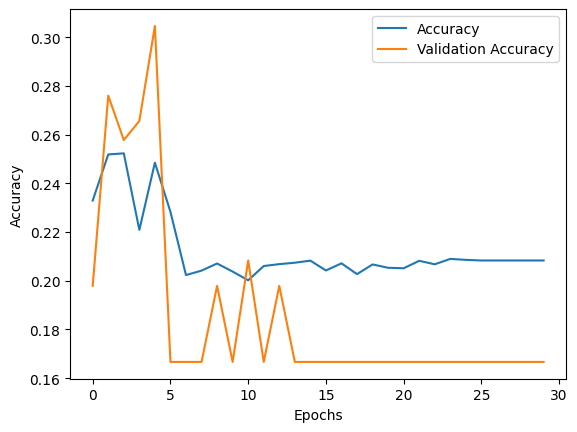

In [13]:
# Визуализация процесса обучения
plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step
[[ 0  0 80  0  0]
 [ 0  0 82  0  0]
 [ 0  0 64  0  0]
 [ 0  0 82  0  0]
 [ 0  0 76  0  0]]


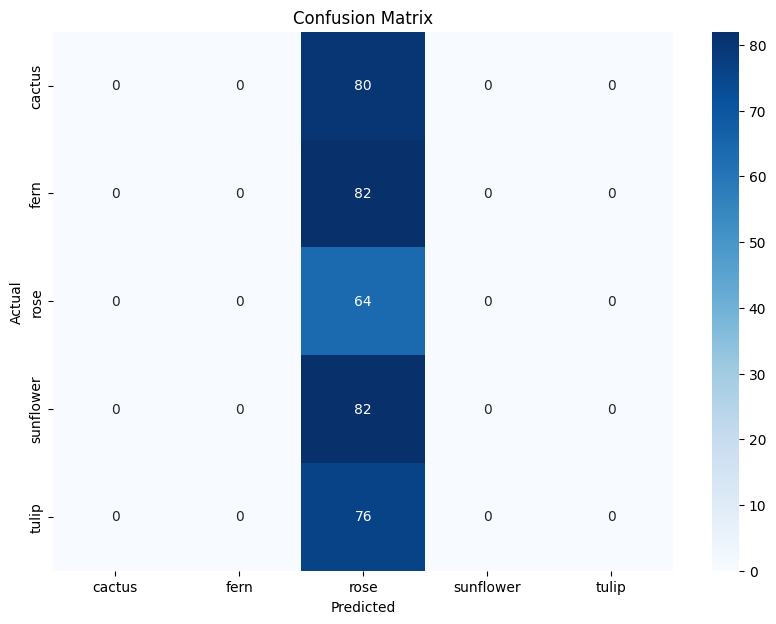

              precision    recall  f1-score   support

      cactus       0.00      0.00      0.00        80
        fern       0.00      0.00      0.00        82
        rose       0.17      1.00      0.29        64
   sunflower       0.00      0.00      0.00        82
       tulip       0.00      0.00      0.00        76

    accuracy                           0.17       384
   macro avg       0.03      0.20      0.06       384
weighted avg       0.03      0.17      0.05       384



c:\Users\annal\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\annal\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\annal\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

In [19]:
# Получение предсказаний от модели
y_pred_probs = model.predict(X_test_processed)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

# Кодировка y_test
y_test_encoded = label_encoder.transform(y_test)

# Импорт для визуализации
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Матрица путаницы
conf_matrix = confusion_matrix(y_test_encoded, y_pred_classes)
print(conf_matrix)

# Визуализация матрицы путаницы
plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Отчет о классификации
print(classification_report(y_test_encoded, y_pred_classes, target_names=label_encoder.classes_))

Выполняем тесты

In [ ]:
import os
from docx import Document
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt_tab')

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('russian'))
custom_stopwords = {'dart', 'flutter', 'http', 'https', 'com', 'io', 'package', 'material', 'widgets', 'class', 'void', 
                    'import', 'const', 'final', 'string', 'override', 'child', 'data', 'get', 'return', 'extends', 'context', 
                    'locale', 'this', 'the', 'api', 'homedata', 'name'}

def preprocess_text(text):
    """Предобработка текста: токенизация, удаление стоп-слов, лемматизация"""
    tokens = nltk.word_tokenize(text.lower(), language='russian')
    words = [word for word in tokens if word.isalnum()]
    words = [word for word in words if word not in stop_words and word not in custom_stopwords]
    lemmatized = [lemmatizer.lemmatize(word) for word in words]
    return ' '.join(lemmatized)

# Загрузка и предобработка документов
folder_path = '..\\static\\csv\\pmu'
texts = []
file_names = []

for file_name in os.listdir(folder_path):
    if file_name.endswith('.docx'):
        try:
            doc = Document(os.path.join(folder_path, file_name))
            text = ' '.join([paragraph.text for paragraph in doc.paragraphs])
            texts.append(text)
            file_names.append(file_name)
        except Exception as e:
            print(f"Ошибка при чтении файла {file_name}: {e}")

preprocessed_texts = [preprocess_text(text) for text in texts]

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\annal\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\annal\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\annal\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\annal\AppData\Roaming\nltk_data...
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\annal\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


Векторизируем текст

In [26]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

tokenizer = Tokenizer(num_words=5000, oov_token="<OOV>")
tokenizer.fit_on_texts(preprocessed_texts)
sequences = tokenizer.texts_to_sequences(preprocessed_texts)


max_length = 512
padded_sequences = pad_sequences(sequences, maxlen=max_length, padding='post', truncating='post')

In [27]:
from matplotlib import pyplot as plt
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split

# Использование кластеров из 8 лабораторной как метки классов
vectorizer = CountVectorizer(max_features=5000)
bow_matrix = vectorizer.fit_transform(preprocessed_texts)
num_clusters = 5
kmeans = KMeans(n_clusters=num_clusters, random_state=42)
clusters = kmeans.fit_predict(bow_matrix)
y = clusters

# Разделение данных на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(padded_sequences, y, test_size=0.2, random_state=42)

# Построение графиков обучения
def plot_history(history, title):
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title(f'{title} Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'{title} Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

Создадим полносзязную модель

c:\Users\annal\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


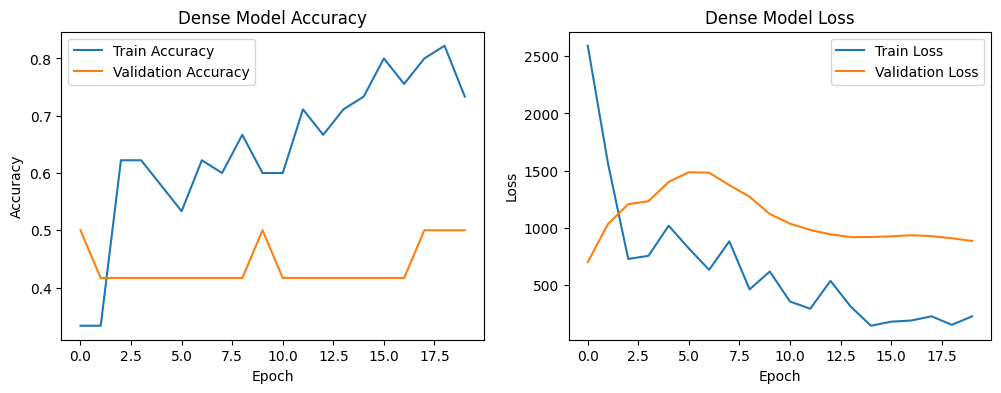

In [28]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

model_dense = Sequential([
    Dense(256, activation='relu', input_shape=(max_length,)),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(num_clusters, activation='softmax')
])

model_dense.compile(optimizer=Adam(learning_rate=0.001), 
                   loss='sparse_categorical_crossentropy', 
                   metrics=['accuracy'])

history_dense = model_dense.fit(X_train, y_train, 
                                epochs=20, 
                                validation_data=(X_test, y_test), 
                                batch_size=32, 
                                verbose=0)

plot_history(history_dense, 'Dense Model')

Создадим свёрточную модель

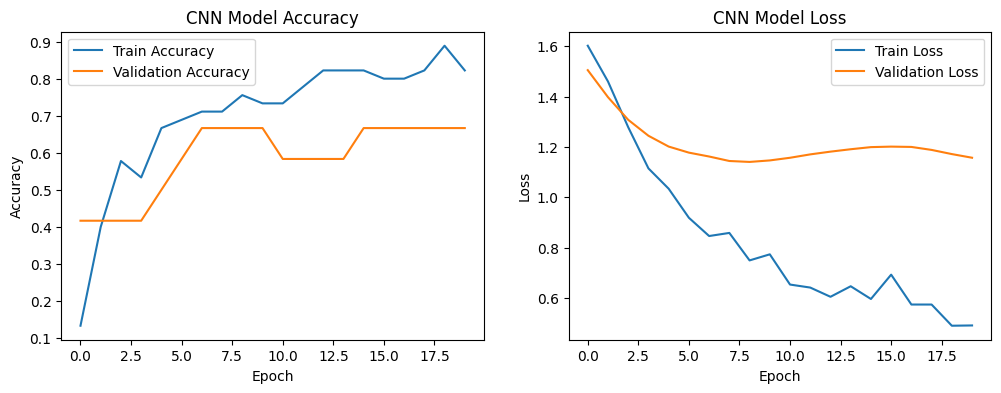

In [29]:
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D

model_cnn = Sequential([
    Embedding(input_dim=5000, output_dim=128),
    Conv1D(filters=128, kernel_size=5, activation='relu'),
    GlobalMaxPooling1D(),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(num_clusters, activation='softmax')
])

model_cnn.compile(optimizer='adam', 
                 loss='sparse_categorical_crossentropy', 
                 metrics=['accuracy'])

history_cnn = model_cnn.fit(X_train, y_train, 
                            epochs=20, 
                            validation_data=(X_test, y_test), 
                            batch_size=32, 
                            verbose=0)

plot_history(history_cnn, 'CNN Model')

Создадим рекурентную модель

c:\Users\annal\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


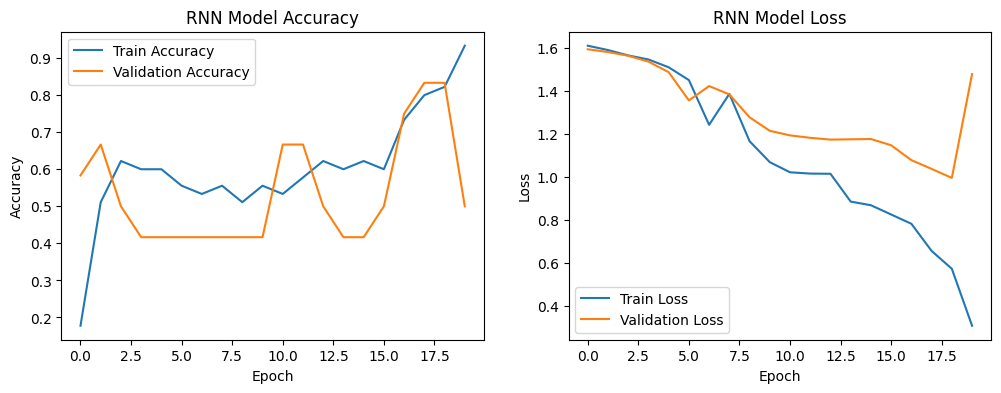

In [30]:
from tensorflow.keras.layers import LSTM

model_rnn = Sequential([
    Embedding(input_dim=5000, output_dim=128, input_length=max_length),
    LSTM(128, return_sequences=False),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(num_clusters, activation='softmax')
])

model_rnn.compile(optimizer='adam', 
                 loss='sparse_categorical_crossentropy', 
                 metrics=['accuracy'])

history_rnn = model_rnn.fit(X_train, y_train, 
                            epochs=20, 
                            validation_data=(X_test, y_test), 
                            batch_size=32, 
                            verbose=0)

plot_history(history_rnn, 'RNN Model')

Сравним полученные модели

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step


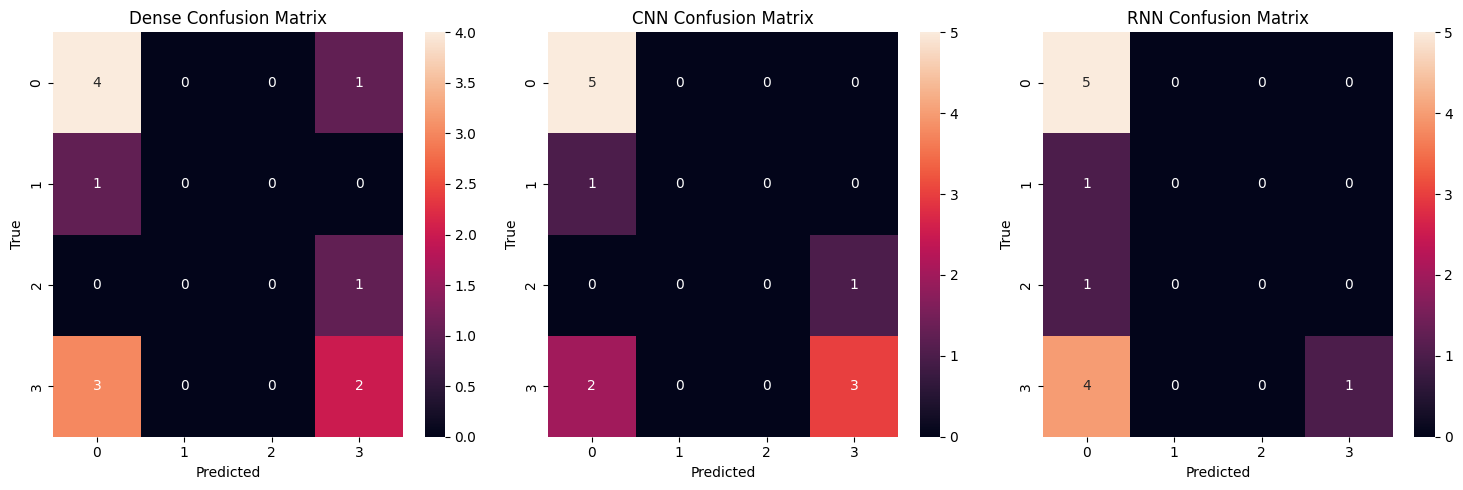


Dense Classification Report:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
              precision    recall  f1-score   support

           1       0.50      0.80      0.62         5
           2       0.00      0.00      0.00         1
           3       0.00      0.00      0.00         1
           4       0.50      0.40      0.44         5

    accuracy                           0.50        12
   macro avg       0.25      0.30      0.26        12
weighted avg       0.42      0.50      0.44        12


CNN Classification Report:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
              precision    recall  f1-score   support

           1       0.62      1.00      0.77         5
           2       0.00      0.00      0.00         1
           3       0.00      0.00      0.00         1
           4       0.75      0.60      0.67         5

    accuracy                           0.67        12
   macro avg       0.34      0.40      0.36        12
weighted avg       0.57      0.67      0.60        

In [31]:
import seaborn as sns
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_models(models):
    plt.figure(figsize=(15, 5))
    for i, (name, model) in enumerate(models.items(), 1):
        plt.subplot(1, 3, i)
        y_pred = model.predict(X_test)
        y_pred_classes = np.argmax(y_pred, axis=1)
        cm = confusion_matrix(y_test, y_pred_classes)
        sns.heatmap(cm, annot=True, fmt='d')
        plt.title(f'{name} Confusion Matrix')
        plt.xlabel('Predicted')
        plt.ylabel('True')
    plt.tight_layout()
    plt.show()
    
    for name, model in models.items():
        print(f"\n{name} Classification Report:")
        y_pred = model.predict(X_test)
        y_pred_classes = np.argmax(y_pred, axis=1)
        print(classification_report(y_test, y_pred_classes, zero_division=0.0))

models = {
    'Dense': model_dense,
    'CNN': model_cnn,
    'RNN': model_rnn
}

evaluate_models(models)

Исследуем влияние гиперпараметров на Dense модели

In [32]:
learning_rates = [0.001, 0.01]
dropout_rates = [0.3, 0.5]

print("Эксперименты с гиперпараметрами для Dense модели:")
for lr in learning_rates:
    for dr in dropout_rates:
        model = Sequential([
            Dense(256, activation='relu', input_shape=(max_length,)),
            Dropout(dr),
            Dense(128, activation='relu'),
            Dropout(dr),
            Dense(num_clusters, activation='softmax')
        ])
        model.compile(optimizer=Adam(learning_rate=lr), 
                     loss='sparse_categorical_crossentropy', 
                     metrics=['accuracy'])
        history = model.fit(X_train, y_train, 
                            epochs=10, 
                            validation_data=(X_test, y_test), 
                            verbose=0)
        val_acc = max(history.history['val_accuracy'])
        print(f"Learning Rate: {lr}, Dropout: {dr} -> Max Val Accuracy: {val_acc:.4f}")

Эксперименты с гиперпараметрами для Dense модели:


c:\Users\annal\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Learning Rate: 0.001, Dropout: 0.3 -> Max Val Accuracy: 0.5833
Learning Rate: 0.001, Dropout: 0.5 -> Max Val Accuracy: 0.5000
Learning Rate: 0.01, Dropout: 0.3 -> Max Val Accuracy: 0.5000
Learning Rate: 0.01, Dropout: 0.5 -> Max Val Accuracy: 0.5833
